# Segmentación de clientes mayoristas para la planificación logística

**Gestión de Proyectos de Datos · SCY1102 · Evaluación 3**  
**Proyecto** · Distribuidora Alimentos del Pacífico S.A.  
**Equipo 3** · Vicente Tapia y Adriano Contreras  
**Fecha de entrega** · 24/11/20226



## Objetivo general

Desarrollar un prototipo reproducible que agrupe clientes mayoristas según su gasto anual por categoría y permita asignar clientes nuevos a los perfiles identificados, para orientar decisiones de despacho, stock y promociones.

## Objetivos específicos

- Revisar y documentar la calidad de las seis variables de gasto y describir su distribución.
- Comparar K-means y agrupamiento jerárquico para 2 a 6 grupos, considerando separación y estabilidad.
- Caracterizar cada perfil y proponer cómo usarlo para agrupar despachos, revisar inventario y enfocar promociones.
- Demostrar el uso del modelo con clientes ficticios que ingresan después del entrenamiento.

## Problema

La Distribuidora Alimentos del Pacífico S.A. atiende a restaurantes, cafés, hoteles y minoristas con patrones de compra diferentes. La información histórica de gasto se ha usado poco para distinguir qué familias de productos conviene priorizar al organizar despachos, preparar inventario o diseñar promociones.

## Contexto de los datos

El archivo `Wholesale customers data.csv` contiene **440 registros** de clientes mayoristas, con **seis gastos anuales** en unidades monetarias, canal y región. El archivo carece de fechas que permitan identificar el año de referencia.

## Metodología CRISP-DM

| Fase | Resultado en el notebook |
| --- | --- |
| 1. Comprensión del negocio | Necesidades, alcance y criterios de aceptación técnica |
| 2. Comprensión de los datos | Diccionario, diagnóstico y exploración del gasto |
| 3. Preparación de los datos | Base conciliada y transformaciones reproducibles |
| 4. Modelado | Comparación de algoritmos, escalado y número de grupos |
| 5. Evaluación | Selección, perfiles, estabilidad y usos propuestos |
| 6. Despliegue | Demostración de asignación de clientes nuevos |

Si la solución queda por debajo de las metas técnicas, se revisa la preparación o el modelado antes de proponer su uso operativo. Las metas corresponden a la planificación de la Evaluación 2.

## Fase 1. Comprensión del negocio

Distribuidora Alimentos del Pacífico S.A. abastece a restaurantes, cafeterías, hoteles y comercios minoristas. Estos clientes tienen patrones de compra distintos, pero la empresa los atiende de manera similar al planificar los despachos, gestionar el inventario y ofrecer promociones. Aunque dispone de registros históricos de facturación por categoría de producto, todavía no los analiza de forma sistemática para distinguir esas diferencias.

La empresa solicita identificar perfiles de clientes mayoristas con patrones de compra similares. Para ello, el proyecto debe revisar y preparar los registros de facturación, analizar el gasto por categoría y agrupar a los clientes según sus hábitos de compra. La empresa también solicita un panel de visualización para que Operaciones consulte los perfiles y un informe de recomendaciones que traduzca los hallazgos en propuestas concretas.

La segmentación busca apoyar tres decisiones del negocio:
- Transporte y Rutas: identificar qué clientes podrían agruparse en un mismo viaje y orientar la planificación de los despachos.
- Bodega y Abastecimiento: reconocer qué categorías conviene priorizar al revisar los niveles de stock.
- Comercial: diseñar promociones acordes con los productos que más compra cada perfil.
Con este proyecto, la Gerencia de Operaciones y Logística busca mejorar el nivel de servicio y reducir los costos logísticos mediante una atención que tenga en cuenta las diferencias entre sus clientes.

## Fase 2. Comprensión de los datos

| Columna del CSV | Significado | Uso |
| --- | --- | --- |
| `Fresh` | Productos frescos | Segmentación |
| `Milk` | Lácteos | Segmentación |
| `Grocery` | Abarrotes | Segmentación |
| `Frozen` | Congelados | Segmentación |
| `Detergents_Paper` | Detergentes y papel | Segmentación |
| `Delicassen` | Productos delicatessen | Segmentación |
| `Channel` | Canal · 1 Horeca, 2 minorista | Descripción de perfiles |
| `Region` | Región · 1 Lisboa, 2 Oporto, 3 otras | Descripción de perfiles |

Horeca agrupa clientes de hotelería, restaurantes y cafeterías. Los seis gastos corresponden a montos anuales. Se usa el nombre `Delicassen` tal como aparece en el archivo. El conjunto incluye el canal comercial, pero carece de una etiqueta de segmento a predecir.


In [15]:
from hashlib import sha256
from pathlib import Path
import platform

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, RobustScaler, StandardScaler

SEMILLA = 42
ARCHIVO = "Wholesale customers data.csv"
CATEGORIAS = {
    "Fresh": "Frescos",
    "Milk": "Lácteos",
    "Grocery": "Abarrotes",
    "Frozen": "Congelados",
    "Detergents_Paper": "Detergentes y papel",
    "Delicassen": "Delicatessen",
}
GASTOS = list(CATEGORIAS)
CANALES = {1: "Horeca", 2: "Minorista"}
REGIONES = {1: "Lisboa", 2: "Oporto", 3: "Otras regiones"}

ruta_csv = Path(ARCHIVO)
if not ruta_csv.is_file():
    ruta_csv = Path("upload") / ARCHIVO
if not ruta_csv.is_file():
    raise FileNotFoundError(f"Sube el archivo {ARCHIVO} al directorio de trabajo.")

datos = pd.read_csv(ruta_csv)
columnas_esperadas = ["Channel", "Region", *GASTOS]
faltantes = set(columnas_esperadas) - set(datos.columns)
if faltantes:
    raise ValueError(f"Faltan columnas en el CSV: {sorted(faltantes)}")

print(f"Fuente: {ruta_csv.name} | {datos.shape[0]} filas y {datos.shape[1]} columnas")

display(datos.head())

Fuente: Wholesale customers data.csv | 440 filas y 8 columnas


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [2]:
gastos_fuente = datos[GASTOS]
gastos_numericos = gastos_fuente.apply(pd.to_numeric, errors="coerce")
valores_finitos = np.isfinite(gastos_numericos)
diagnostico = pd.DataFrame({
    "Tipo en el CSV": datos.dtypes,
    "Nulos": datos.isna().sum(),
    "Valores distintos": datos.nunique(),
})
display(diagnostico)
print(f"Filas duplicadas exactas adicionales: {datos.duplicated().sum()}")
print(f"Gastos negativos: {gastos_numericos.lt(0).sum().sum()}")
print(f"Gastos ausentes, no numéricos o infinitos: {(~valores_finitos).sum().sum()}")

if not valores_finitos.to_numpy().all() or gastos_numericos.lt(0).to_numpy().any():
    raise ValueError("Revisa el CSV: los gastos deben ser numéricos, finitos y no negativos.")
if not datos["Channel"].isin(CANALES).all() or not datos["Region"].isin(REGIONES).all():
    raise ValueError("El CSV contiene canales o regiones fuera de los códigos documentados.")

canal = datos["Channel"].map(CANALES).rename("Canal")
region = datos["Region"].map(REGIONES).rename("Región")
display(pd.crosstab(canal, region, margins=True, margins_name="Total"))
display(gastos_numericos.rename(columns=CATEGORIAS).describe().T.round(1))

,Tipo en el CSV,Nulos,Valores distintos
Channel,int64,0,2
Region,int64,0,3
Fresh,int64,0,433
Milk,int64,0,421
Grocery,int64,0,430
Frozen,int64,0,426
Detergents_Paper,int64,0,417
Delicassen,int64,0,403


Filas duplicadas exactas adicionales: 0
Gastos negativos: 0
Gastos ausentes, no numéricos o infinitos: 0


Región,Lisboa,Oporto,Otras regiones,Total
Canal,,,,
Horeca,59,28,211,298
Minorista,18,19,105,142
Total,77,47,316,440


,count,mean,std,min,25%,50%,75%,max
Frescos,440.0,12000.3,12647.3,3.0,3127.8,8504.0,16933.8,112151.0
Lácteos,440.0,5796.3,7380.4,55.0,1533.0,3627.0,7190.2,73498.0
Abarrotes,440.0,7951.3,9503.2,3.0,2153.0,4755.5,10655.8,92780.0
Congelados,440.0,3071.9,4854.7,25.0,742.2,1526.0,3554.2,60869.0
Detergentes y papel,440.0,2881.5,4767.9,3.0,256.8,816.5,3922.0,40827.0
Delicatessen,440.0,1524.9,2820.1,3.0,408.2,965.5,1820.2,47943.0


La base contiene 440 registros. La revisión encontró cero valores nulos, cero filas duplicadas exactas y cero gastos negativos, no numéricos o infinitos. Se conservaron todos los registros. Aunque Channel y Region se almacenan como enteros, representan categorías.

El canal Horeca concentra 298 clientes (67,7 %) y el minorista, 142. En cuanto a la ubicación, Otras regiones reúne 316 clientes (71,8 %), seguida de Lisboa (77) y Oporto (47). Esto muestra que la muestra se concentra en el canal Horeca y en la categoría Otras regiones.

Frescos presenta la mayor mediana de gasto anual, con 8.504 unidades monetarias, seguido de abarrotes, con 4.755,5. En las seis categorías, el promedio supera a la mediana, lo que sugiere que los gastos altos elevan el promedio. Por eso la mediana resulta más representativa para describir el gasto típico de un cliente.

,Límite superior,Registros por encima
Frescos,37642.8,20
Lácteos,15676.1,28
Abarrotes,23409.9,24
Congelados,7772.2,43
Detergentes y papel,9419.9,30
Delicatessen,3938.2,27


Clientes por encima del límite en alguna categoría: 108


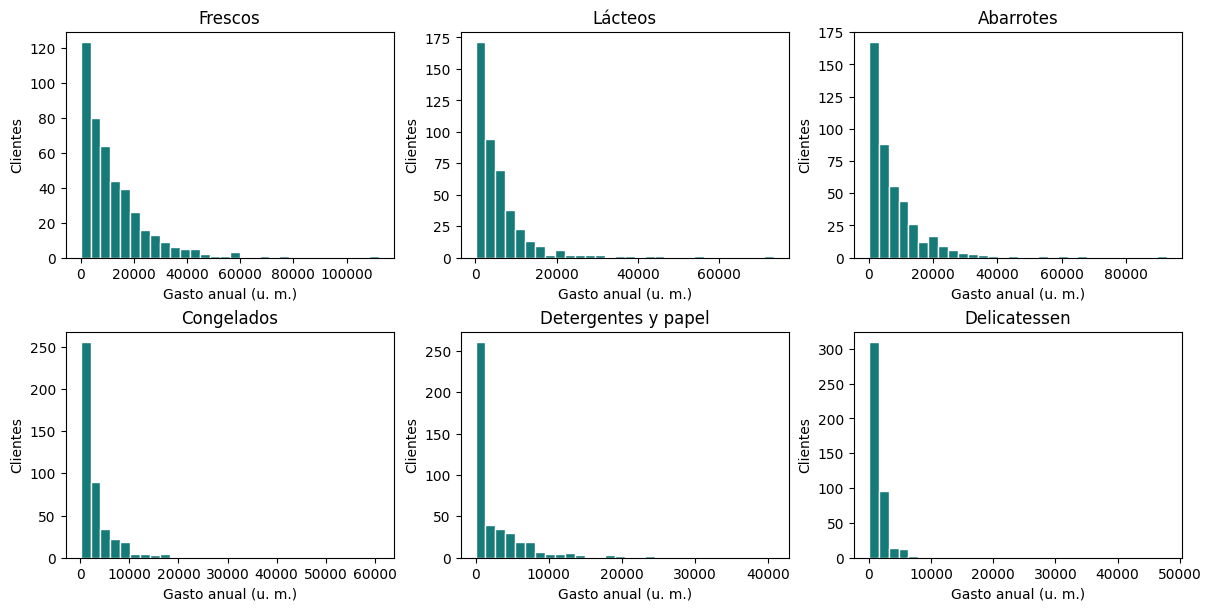

In [3]:
q1 = gastos_numericos.quantile(0.25)
q3 = gastos_numericos.quantile(0.75)
limites_iqr = q3 + 1.5 * (q3 - q1)
atipicos_altos = gastos_numericos.gt(limites_iqr)
display(pd.DataFrame({
    "Límite superior": limites_iqr.round(1),
    "Registros por encima": atipicos_altos.sum(),
}).rename(index=CATEGORIAS))
print(f"Clientes por encima del límite en alguna categoría: {atipicos_altos.any(axis=1).sum()}")

fig, ejes = plt.subplots(2, 3, figsize=(12, 6), layout="constrained")
for eje, columna in zip(ejes.flat, GASTOS):
    eje.hist(gastos_numericos[columna], bins=30, color="#157A78", edgecolor="white")
    eje.set(title=CATEGORIAS[columna], xlabel="Gasto anual (u. m.)", ylabel="Clientes")
plt.show()

**Distribución del gasto anual por categoría**

Cada histograma muestra cuántos clientes se ubican en cada rango de gasto anual. En las seis categorías, la mayoría de los clientes se concentra en los rangos de menor gasto, mientras que unos pocos registran montos muy altos. Esta asimetría hacia la derecha se aprecia especialmente en congelados, detergentes y papel, y delicatessen. Por eso se aplicó la transformación log1p antes del escalado, para reducir la influencia de los gastos más altos en la segmentación

In [4]:
correlaciones = gastos_numericos.rename(columns=CATEGORIAS).corr(method="spearman")
display(correlaciones.round(2))

,Frescos,Lácteos,Abarrotes,Congelados,Detergentes y papel,Delicatessen
Frescos,1.00,-0.08,-0.12,0.38,-0.20,0.24
Lácteos,-0.08,1.00,0.77,-0.09,0.68,0.37
Abarrotes,-0.12,0.77,1.00,-0.17,0.80,0.30
Congelados,0.38,-0.09,-0.17,1.00,-0.21,0.23
Detergentes y papel,-0.20,0.68,0.80,-0.21,1.00,0.18
Delicatessen,0.24,0.37,0.30,0.23,0.18,1.00


El CSV tiene 298 clientes Horeca y 142 minoristas. Los histogramas muestran asimetría hacia gastos altos. **108 clientes** superan el límite superior de Tukey en al menos una categoría. El umbral identifica valores para revisar y por sí solo no prueba un error. La correlación de Spearman muestra que abarrotes y detergentes/papel tienden a subir juntos. En la interpretación se consideran como categorías distintas que pueden reflejar un mismo patrón comercial.

## Fase 3. Preparación de los datos

Se conserva el archivo original. El identificador técnico se genera según el orden de cada fila y permite conciliar los resultados con este CSV. En la base entregada se mantienen los 440 registros. Los duplicados exactos se revisan antes de descartar filas, ya que el archivo carece de identificadores de negocio.

Las seis variables de gasto se transforman dentro del pipeline. `log1p` comprime las diferencias entre montos muy altos y admite ceros. Luego se compara `StandardScaler` (media y desviación estándar) con `RobustScaler` (mediana y rango intercuartílico). Ambos se ajustan con los datos de cada corrida, de modo que los remuestreos también miden la sensibilidad del preprocesamiento.

In [5]:
base = datos[columnas_esperadas].copy()
base.insert(0, "ID técnico", np.arange(1, len(base) + 1))
base[GASTOS] = gastos_numericos
X = base[GASTOS]

conciliacion = pd.DataFrame({
    "Total fuente": gastos_numericos.sum(),
    "Total base analítica": X.sum(),
}).rename(index=CATEGORIAS)
conciliacion["Diferencia"] = conciliacion["Total base analítica"] - conciliacion["Total fuente"]
assert len(base) == len(datos)
assert conciliacion["Diferencia"].eq(0).all()
display(conciliacion)
print(f"{len(base)} de {len(datos)} filas conciliadas. Se conservan los gastos altos observados.")

,Total fuente,Total base analítica,Diferencia
Frescos,5280131,5280131,0
Lácteos,2550357,2550357,0
Abarrotes,3498562,3498562,0
Congelados,1351650,1351650,0
Detergentes y papel,1267857,1267857,0
Delicatessen,670943,670943,0


440 de 440 filas conciliadas. Se conservan los gastos altos observados.


## Fase 4. Modelado

Se comparan **20 configuraciones**: dos escalados, dos algoritmos y cinco valores de `k` (2 a 6). K-means asigna cada cliente al centroide más cercano en el espacio transformado. El método jerárquico de Ward une grupos buscando minimizar el aumento de la variación dentro de ellos y sirve como referencia de comparación.

- **Silhouette** evalúa qué tan cerca está cada cliente de su propio grupo frente a otros. Varía entre −1 y 1. Un valor más alto indica mejor separación según la distancia utilizada. Se calcula sobre las mismas variables transformadas que recibe cada modelo.
- **ARI** compara dos agrupaciones aunque cambien los números de sus etiquetas. Un valor de 1 indica coincidencia completa y un valor cercano a 0 indica concordancia similar a la esperada por azar. Se ajusta de nuevo el pipeline en 10 submuestras reproducibles del 80 % sin reemplazo. Para cada una, se comparan sus etiquetas con las del ajuste completo sobre esas mismas filas. Se informa la mediana de esos 10 valores.

El ARI de este ejercicio mide estabilidad interna frente a cambios en la muestra. Para comprobar que los perfiles funcionan con clientes de la distribuidora se requiere una evaluación con sus propios datos.

In [6]:
def crear_pipeline(escalado, algoritmo, k):
    escalador = StandardScaler() if escalado == "StandardScaler" else RobustScaler()
    if algoritmo == "K-means":
        agrupador = KMeans(n_clusters=k, random_state=SEMILLA, n_init=20)
    else:
        agrupador = AgglomerativeClustering(n_clusters=k, linkage="ward")

    return Pipeline([
        ("log1p", FunctionTransformer(np.log1p)),
        ("escalado", escalador),
        ("agrupador", agrupador),
    ])


rng = np.random.default_rng(SEMILLA)
indices_remuestreo = [
    np.sort(rng.choice(len(X), size=int(0.8 * len(X)), replace=False))
    for _ in range(10)
]

resultados = []
for escalado in ("StandardScaler", "RobustScaler"):
    for algoritmo in ("K-means", "Jerárquico Ward"):
        for k in range(2, 7):
            candidato = crear_pipeline(escalado, algoritmo, k)
            etiquetas = candidato.fit_predict(X)
            X_transformado = candidato[:-1].transform(X)
            valores_ari = []
            for indices in indices_remuestreo:
                submuestra = X.iloc[indices]
                etiquetas_sub = crear_pipeline(escalado, algoritmo, k).fit_predict(submuestra)
                valores_ari.append(adjusted_rand_score(etiquetas[indices], etiquetas_sub))

            resultados.append({
                "Escalado": escalado,
                "Algoritmo": algoritmo,
                "k": k,
                "Silhouette": silhouette_score(X_transformado, etiquetas),
                "ARI mediano": np.median(valores_ari),
                "Grupo menor (n)": np.bincount(etiquetas).min(),
                "ARI por remuestreo": valores_ari,
            })

comparacion = pd.DataFrame(resultados).sort_values(
    ["Silhouette", "ARI mediano", "k"], ascending=[False, False, True]
).reset_index(drop=True)
display(comparacion.drop(columns="ARI por remuestreo").round(3))

,Escalado,Algoritmo,k,Silhouette,ARI mediano,Grupo menor (n)
0,StandardScaler,K-means,2,0.290,0.966,188
1,StandardScaler,Jerárquico Ward,2,0.258,0.437,178
2,StandardScaler,K-means,3,0.258,0.928,83
3,StandardScaler,Jerárquico Ward,3,0.255,0.516,53
4,RobustScaler,K-means,2,0.253,0.983,188
5,RobustScaler,K-means,3,0.245,0.931,80
6,RobustScaler,Jerárquico Ward,3,0.243,0.514,49
7,RobustScaler,Jerárquico Ward,2,0.235,0.458,175
8,StandardScaler,Jerárquico Ward,5,0.203,0.437,18
9,StandardScaler,Jerárquico Ward,4,0.202,0.464,53


## Fase 5. Evaluación del modelo

### Justificación de la configuración elegida

De las 20 configuraciones comparadas, se eligió **K-means con `StandardScaler` y `k = 2`** (fila 0 de la tabla). El pipeline aplica primero `log1p`, luego el escalado estándar y, por último, K-means sobre las seis variables de gasto.

**Criterio de selección.** La configuración debía alcanzar **Silhouette ≥ 0,25** y **ARI mediano ≥ 0,70**, además de contar con `predict` para asignar nuevos clientes. Silhouette mide la separación de los grupos y el ARI mediano resume la estabilidad en los 10 remuestreos. Entre las opciones que cumplen ambos mínimos, se prioriza el Silhouette y se usa el ARI mediano para desempatar.

| Configuración elegible | Silhouette | ARI mediano |
| --- | ---: | ---: |
| **K-means · StandardScaler · k = 2** | **0,290** | **0,966** |
| K-means · StandardScaler · k = 3 | 0,258 | 0,928 |
| K-means · RobustScaler · k = 2 | 0,253 | 0,983 |

Con dos grupos, el escalado estándar obtuvo el mayor Silhouette de las 20 pruebas y superó ampliamente la meta de estabilidad. El escalado robusto obtuvo un ARI mediano mayor, pero un Silhouette menor. Al pasar a tres grupos con el escalado estándar, disminuyeron ambas métricas. Todas las configuraciones de Ward quedaron por debajo del ARI mínimo.

El modelo elegido produjo **252 clientes en el Perfil 1** y **188 en el Perfil 2**. Se usa este mismo pipeline para sugerir el perfil de nuevos clientes en la Fase 6.

In [7]:
META_SILHOUETTE = 0.25
META_ARI = 0.70
elegibles = comparacion.loc[
    comparacion["Silhouette"].ge(META_SILHOUETTE)
    & comparacion["ARI mediano"].ge(META_ARI)
    & comparacion["Algoritmo"].eq("K-means")
]
if elegibles.empty:
    raise ValueError("Ninguna configuración con predict alcanza ambas metas. Revisa los modelos.")

seleccion = elegibles.iloc[0]
modelo_final = crear_pipeline(seleccion["Escalado"], seleccion["Algoritmo"], int(seleccion["k"]))
base["Grupo"] = modelo_final.fit_predict(X)
assert np.array_equal(modelo_final.predict(X), base["Grupo"].to_numpy())

print(
    f"Seleccionado: {seleccion['Algoritmo']} · {seleccion['Escalado']} · "
    f"k = {seleccion['k']}"
)
print(f"Silhouette: {seleccion['Silhouette']:.3f} | ARI mediano: {seleccion['ARI mediano']:.3f}")
display(pd.DataFrame({
    "Remuestreo": range(1, len(indices_remuestreo) + 1),
    "ARI": seleccion["ARI por remuestreo"],
}).round(3).set_index("Remuestreo").T)

Seleccionado: K-means · StandardScaler · k = 2
Silhouette: 0.290 | ARI mediano: 0.966


Remuestreo,1,2,3,4,5,6,7,8,9,10
ARI,1.0,0.989,0.944,0.955,0.955,0.977,1.0,0.911,0.989,0.955


Se seleccionó K-means con StandardScaler y dos grupos porque obtuvo el mayor Silhouette (0,290) entre las configuraciones que cumplieron ambos criterios de selección. El ARI mediano fue de 0,966 y, en los diez remuestreos, varió entre 0,911 y 1,000. Esto indica que las asignaciones se mantuvieron similares al volver a entrenar con distintas submuestras. Con la configuración elegida se entrenó el modelo final y se asignó un grupo a cada uno de los 440 clientes.

In [8]:
# Ordenar los perfiles por su mediana de abarrotes para darles nombres legibles.
medianas = base.groupby("Grupo")[GASTOS].median()
grupos_ordenados = medianas["Grocery"].sort_values().index
perfiles = {grupo: f"Perfil {i}" for i, grupo in enumerate(grupos_ordenados, start=1)}
base["Perfil"] = base["Grupo"].map(perfiles)

medianas_perfil = base.groupby("Perfil")[GASTOS].median()
tamanos = base["Perfil"].value_counts().sort_index().rename("Clientes").to_frame()
tamanos["% de la base"] = (100 * tamanos["Clientes"] / len(base)).round(1)
tamanos["Interpretación"] = np.where(tamanos["Clientes"] < 30, "Exploratoria", "n ≥ 30")
display(tamanos.join(medianas_perfil.rename(columns=CATEGORIAS)))
display(pd.crosstab(base["Perfil"], canal))
display(pd.crosstab(base["Perfil"], region))

,Clientes,% de la base,Interpretación,Frescos,Lácteos,Abarrotes,Congelados,Detergentes y papel,Delicatessen
Perfil,,,,,,,,,
Perfil 1,252,57.3,n ≥ 30,10347.5,1871.0,2406.0,2225.0,327.5,749.5
Perfil 2,188,42.7,n ≥ 30,5406.5,7690.5,11527.0,1061.5,4495.0,1388.5


Canal,Horeca,Minorista
Perfil,,
Perfil 1,244,8
Perfil 2,54,134


Región,Lisboa,Oporto,Otras regiones
Perfil,,,
Perfil 1,48,28,176
Perfil 2,29,19,140


El Perfil 1 reúne a 252 clientes (57,3 % de la base). Su gasto anual mediano es mayor que el del otro perfil en frescos y congelados. Además, 244 de sus 252 clientes pertenecen al canal Horeca.

El Perfil 2 reúne a 188 clientes (42,7 % de la base). Presenta un gasto mediano más alto en abarrotes, lácteos, detergentes y papel, y delicatessen. En abarrotes, su mediana alcanza 11.527 unidades monetarias, frente a 2.406 en el Perfil 1. En este grupo predominan los minoristas, con 134 de los 188 clientes.

Ambos perfiles tienen presencia en las tres regiones y concentran la mayoría de sus clientes en Otras regiones. Las diferencias más claras entre los perfiles se observan en el patrón de gasto y en el canal predominante.

### Fichas de los perfiles

La ficha muestra el número de clientes, la mediana del **gasto total anual por cliente** y el peso promedio de cada categoría en su canasta. El gasto total de cada cliente se calcula sumando sus seis categorías antes de obtener la mediana del perfil.

Para cada cliente con gasto positivo se divide el gasto en cada categoría por su gasto total. Después se promedian esos porcentajes dentro del perfil. Así cada cliente pesa igual en la composición. La suma de porcentajes puede diferir de 100 % por redondeo.

In [9]:
gasto_total = X.sum(axis=1)
gasto_tipico = gasto_total.groupby(base["Perfil"]).median()
ficha = tamanos[["Clientes", "% de la base"]].join(
    gasto_tipico.rename("Gasto anual total mediano (u. m.)")
)
display(ficha.round(1))

participacion_cliente = X.div(gasto_total.where(gasto_total.gt(0)), axis="index") * 100
composicion = participacion_cliente.groupby(base["Perfil"]).mean()
print("Composición promedio del gasto por cliente (%)")
display(composicion.rename(columns=CATEGORIAS).round(1))

,Clientes,% de la base,Gasto anual total mediano (u. m.)
Perfil,,,
Perfil 1,252,57.3,19745.0
Perfil 2,188,42.7,35222.5


Composición promedio del gasto por cliente (%)


,Frescos,Lácteos,Abarrotes,Congelados,Detergentes y papel,Delicatessen
Perfil,,,,,,
Perfil 1,50.8,11.8,14.7,15.2,2.7,4.9
Perfil 2,19.7,23.4,34.1,4.4,13.8,4.6


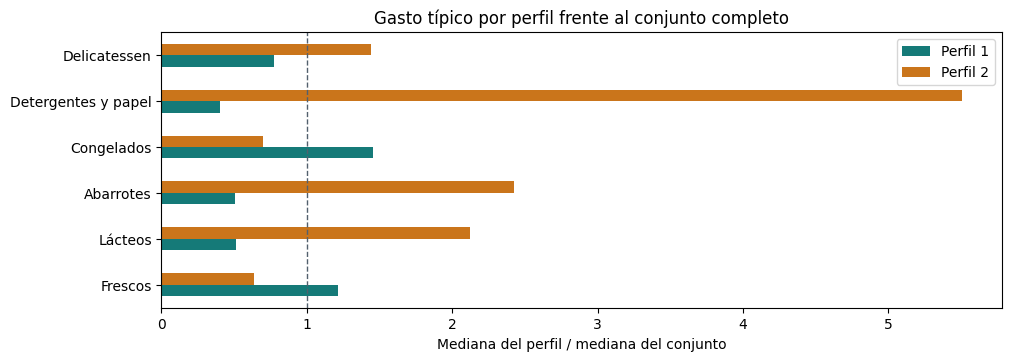

In [10]:
mediana_global = X.median()
mediana_relativa = medianas_perfil.div(mediana_global.where(mediana_global.ne(0)))
fig, eje = plt.subplots(figsize=(10, 3.5), layout="constrained")
mediana_relativa.rename(columns=CATEGORIAS).T.plot.barh(
    ax=eje, color=["#157A78", "#CA751B"],
)
eje.axvline(1, color="#52606D", linestyle="--", linewidth=1)
eje.set(
    title="Gasto típico por perfil frente al conjunto completo",
    xlabel="Mediana del perfil / mediana del conjunto",
    ylabel="",
)
eje.legend(title="")
plt.show()

El gráfico muestra en qué categorías gasta más o menos un cliente típico de cada perfil, comparado con el conjunto de los 440 clientes.

La línea punteada en 1 es la referencia. Para cada categoría, el notebook divide la mediana del gasto anual del perfil por la mediana del gasto anual de todos los clientes en esa misma categoría.
- Igual a 1 significa que el gasto típico del perfil coincide con el del conjunto.
- Mayor que 1 significa que el perfil gasta más. Por ejemplo, 2 equivale al doble.
- Menor que 1 significa que el perfil gasta menos. Por ejemplo, 0,5 equivale a la mitad.

| Perfil | Qué destaca en el gráfico |
| --- | --- |
| **Perfil 1 (verde)** | Gasta por encima de la referencia en **frescos** y **congelados**. En congelados, su gasto típico es aproximadamente **1,5 veces** el del conjunto. |
| **Perfil 2 (naranja)** | Destaca en **detergentes y papel**, **abarrotes** y **lácteos**. En detergentes y papel, su mediana es de **4.495 unidades monetarias**, frente a **816,5** en el conjunto. Por eso la barra llega a **5,5 veces** la referencia. |

### Visualización de los clientes y los centroides con PCA

El análisis de componentes principales (PCA) resume las seis variables de gasto transformadas en dos ejes que concentran la mayor parte posible de su variabilidad. En el panel izquierdo cada punto representa un cliente. En el panel derecho, los colores muestran los perfiles asignados por K-means y las cruces grandes marcan los **centroides**.

Ambos paneles usan la misma proyección. Primero se aplica el preprocesamiento ya ajustado por el pipeline. Luego se ajusta PCA con esos datos y se proyectan los centroides con ese mismo PCA. K-means sigue agrupando a los clientes en las seis dimensiones transformadas.

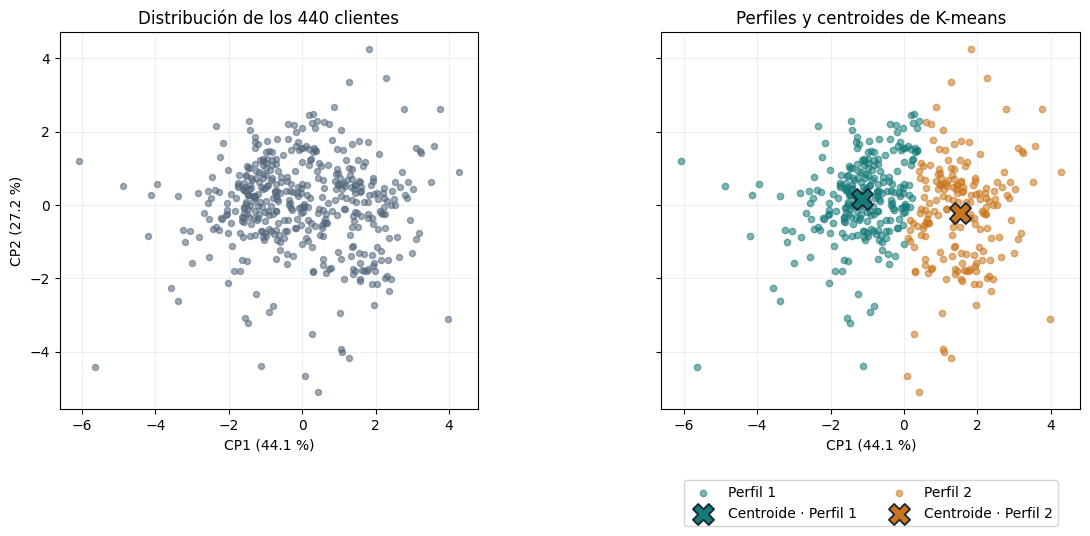

Varianza explicada por CP1 y CP2: 71.3 %


In [11]:
from sklearn.decomposition import PCA

# Los clientes y los centroides ya están en el mismo espacio de seis variables.
X_modelo = modelo_final[:-1].transform(X)
centroides = modelo_final.named_steps["agrupador"].cluster_centers_

pca = PCA(n_components=2)
clientes_pca = pca.fit_transform(X_modelo)
centroides_pca = pca.transform(centroides)
varianza_pct = pca.explained_variance_ratio_ * 100

fig, (eje_clientes, eje_perfiles) = plt.subplots(
    1, 2, figsize=(12, 5.3), sharex=True, sharey=True, layout="constrained"
)
eje_clientes.scatter(
    clientes_pca[:, 0], clientes_pca[:, 1], s=19, color="#52677B", alpha=0.55
)
eje_clientes.set_title("Distribución de los 440 clientes")
eje_perfiles.set_title("Perfiles y centroides de K-means")

colores = plt.get_cmap("tab10").colors
for i, (grupo, perfil) in enumerate(perfiles.items()):
    color = ("#157A78", "#CA751B")[i] if i < 2 else colores[i]
    puntos = clientes_pca[base["Grupo"].eq(grupo)]
    eje_perfiles.scatter(
        puntos[:, 0], puntos[:, 1], s=21, color=color, alpha=0.55, label=perfil
    )
    eje_perfiles.scatter(
        *centroides_pca[grupo], marker="X", s=230, color=color, edgecolors="#182530",
        linewidths=1.3, zorder=3, label=f"Centroide · {perfil}"
    )

for eje in (eje_clientes, eje_perfiles):
    eje.set(xlabel=f"CP1 ({varianza_pct[0]:.1f} %)", aspect="equal")
    eje.grid(alpha=0.20)
    eje.set_axisbelow(True)
eje_clientes.set_ylabel(f"CP2 ({varianza_pct[1]:.1f} %)")
eje_perfiles.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2)
plt.show()
print(f"Varianza explicada por CP1 y CP2: {varianza_pct.sum():.1f} %")

Los porcentajes de los ejes indican cuánta variabilidad del gasto transformado recoge cada componente. Si algunos puntos de perfiles distintos se superponen, el gráfico solo muestra su posición en dos dimensiones. Silhouette y ARI se interpretan a partir del agrupamiento en el espacio de seis variables.

### Interpretación y uso propuesto

**Perfil 1 · Frescos y congelados (252 clientes, 57,3 %).** Sus medianas de frescos y congelados superan las del Perfil 2. En congelados son 2.225 frente a 1.061,5 unidades monetarias. Incluye 244 clientes Horeca y 8 minoristas.

**Perfil 2 · Abarrotes, lácteos y detergentes/papel (188 clientes, 42,7 %).** La mediana de abarrotes alcanza 11.527 unidades monetarias, frente a 2.406 del Perfil 1. Incluye 134 minoristas y 54 clientes Horeca.

En promedio, frescos y congelados representan el 66,0 % de la canasta del Perfil 1. Abarrotes, lácteos y detergentes/papel suman el 71,3 % en el Perfil 2. El Perfil 2 también tiene una mediana mayor de gasto total anual. Las dos fichas permiten distinguir qué categorías predominan y cuánto gasta un cliente típico.

| Área | Acción propuesta para el Perfil 1 | Acción propuesta para el Perfil 2 | Qué medir en un piloto |
| --- | --- | --- | --- |
| Transporte | Agrupar en un mismo viaje pedidos compatibles de frescos y congelados cuando las paradas sean cercanas, con capacidad y condiciones de temperatura adecuadas. | Agrupar pedidos compatibles de abarrotes y lácteos según zona, horario y cadena de frío. Revisar la compatibilidad de los productos de limpieza con la carga. | Costo por entrega y entregas a tiempo |
| Bodega y Abastecimiento | Revisar disponibilidad de frescos y congelados antes de preparar pedidos del perfil. | Revisar disponibilidad de abarrotes, lácteos y detergentes/papel para la preparación de pedidos. | Quiebres de stock por categoría |
| Comercial | Probar promociones de productos frescos o congelados. | Probar promociones de abarrotes o lácteos y ofertas separadas de insumos de limpieza. | Tasa de respuesta y margen por promoción |

El perfil ayuda a decidir **qué pedidos podrían compartir un viaje**. Transporte necesita direcciones, pedidos por fecha, ventanas horarias y capacidad para decidir dónde y cuándo hacerlo. Los gastos anuales orientan qué revisar, mientras que el stock objetivo exige datos de demanda, inventario y plazos de reposición. Las propuestas requieren revisión humana y los indicadores se medirían si se realiza un piloto con datos de la empresa.

### Piloto de despachos agrupados por perfil

**Responsable propuesto:** Transporte y Rutas, con apoyo de Operaciones y Bodega.

1. Seleccionar una zona y levantar una línea base con pedidos, direcciones, ventanas horarias, capacidad, requisitos de temperatura y costos de despacho.
2. En esa misma zona, comparar la planificación habitual con viajes que agrupen pedidos compatibles de clientes del mismo perfil. Usar días y cargas comparables. Mantener las restricciones de capacidad, horario, temperatura y compatibilidad de productos.
3. Medir el **costo por entrega** (costo de los viajes dividido por las entregas completadas) y la **puntualidad** (porcentaje de entregas programadas completadas dentro de su ventana). Considerar ampliar el piloto si baja el costo por entrega, se mantiene la puntualidad y se cumplen las restricciones de carga.

El CSV académico aporta perfiles de gasto. Las métricas del piloto requieren registros de operación de la distribuidora.

## Fase 6. Despliegue del prototipo

Creamos cuatro clientes ficticios con distintos gastos anuales en las seis categorías. Al ejecutar la celda, el modelo entrenado asigna cada cliente al perfil más cercano a su patrón de compra. La tabla muestra sus gastos y el perfil asignado.

In [12]:
clientes_ficticios = pd.DataFrame(
    [
        ("Cliente A", 15000, 1800, 2800, 5200, 350, 750),
        ("Cliente B", 5000, 9500, 14500, 900, 6500, 1800),
        ("Cliente C", 9500, 5000, 6000, 2400, 1400, 1000),
        ("Cliente D", 22000, 2600, 3300, 7700, 450, 1100),
    ],
    columns=["Cliente", *GASTOS],
)

grupos = modelo_final.predict(clientes_ficticios[GASTOS])
clientes_ficticios["Perfil asignado"] = [perfiles[grupo] for grupo in grupos]
display(clientes_ficticios.rename(columns=CATEGORIAS))

,Cliente,Frescos,Lácteos,Abarrotes,Congelados,Detergentes y papel,Delicatessen,Perfil asignado
0,Cliente A,15000,1800,2800,5200,350,750,Perfil 1
1,Cliente B,5000,9500,14500,900,6500,1800,Perfil 2
2,Cliente C,9500,5000,6000,2400,1400,1000,Perfil 2
3,Cliente D,22000,2600,3300,7700,450,1100,Perfil 1
